# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Audrey, Claire, Jonathan"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


### Steps 1 to 3: load the data, separate the inputs and outcome, and encode the outcome

In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA

import umap

train = pd.read_csv("iot_devices_train.csv")
reporting = pd.read_csv("iot_devices_reporting.csv")
print("training set:", train.shape, "  reporting set:", reporting.shape)

X_train = train.drop(columns="device_category")
X_report = reporting.drop(columns="device_category")

encoder = LabelEncoder()
y_train = encoder.fit_transform(train["device_category"])
y_report = encoder.transform(reporting["device_category"])

pd.DataFrame({
    "code": range(len(encoder.classes_)),
    "training samples": np.bincount(y_train),
    "reporting samples": np.bincount(y_report),
}, index=pd.Index(encoder.classes_, name="device"))

/workspaces/ML-Lab-3-Non-linear-Dimensionality-Reduction---t-SNE-and-UMAP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


training set: (900, 298)   reporting set: (900, 298)


,code,training samples,reporting samples
device,,,
TV,0,100,100
baby_monitor,1,100,100
lights,2,100,100
motion_sensor,3,100,100
security_camera,4,100,100
smoke_detector,5,100,100
socket,6,100,100
thermostat,7,100,100
watch,8,100,100


### Steps 4 and 5: PCA and UMAP of the training set

The standardization here is only for these two visualizations. Each pipeline scales the features first and then reduces them to 2 dimensions.

In [ ]:
pca_pipeline = make_pipeline(StandardScaler(), PCA(n_components=2, random_state=42))
umap_pipeline = make_pipeline(StandardScaler(), umap.UMAP(n_components=2, random_state=42, n_jobs=1))

X_pca = pca_pipeline.fit_transform(X_train)
X_umap = umap_pipeline.fit_transform(X_train)
print("share of the variance kept by the 2 PCA components:", pca_pipeline[-1].explained_variance_ratio_.round(3))

/workspaces/ML-Lab-3-Non-linear-Dimensionality-Reduction---t-SNE-and-UMAP/.venv/lib/python3.14/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


share of the variance kept by the 2 PCA components: [0.371 0.274]


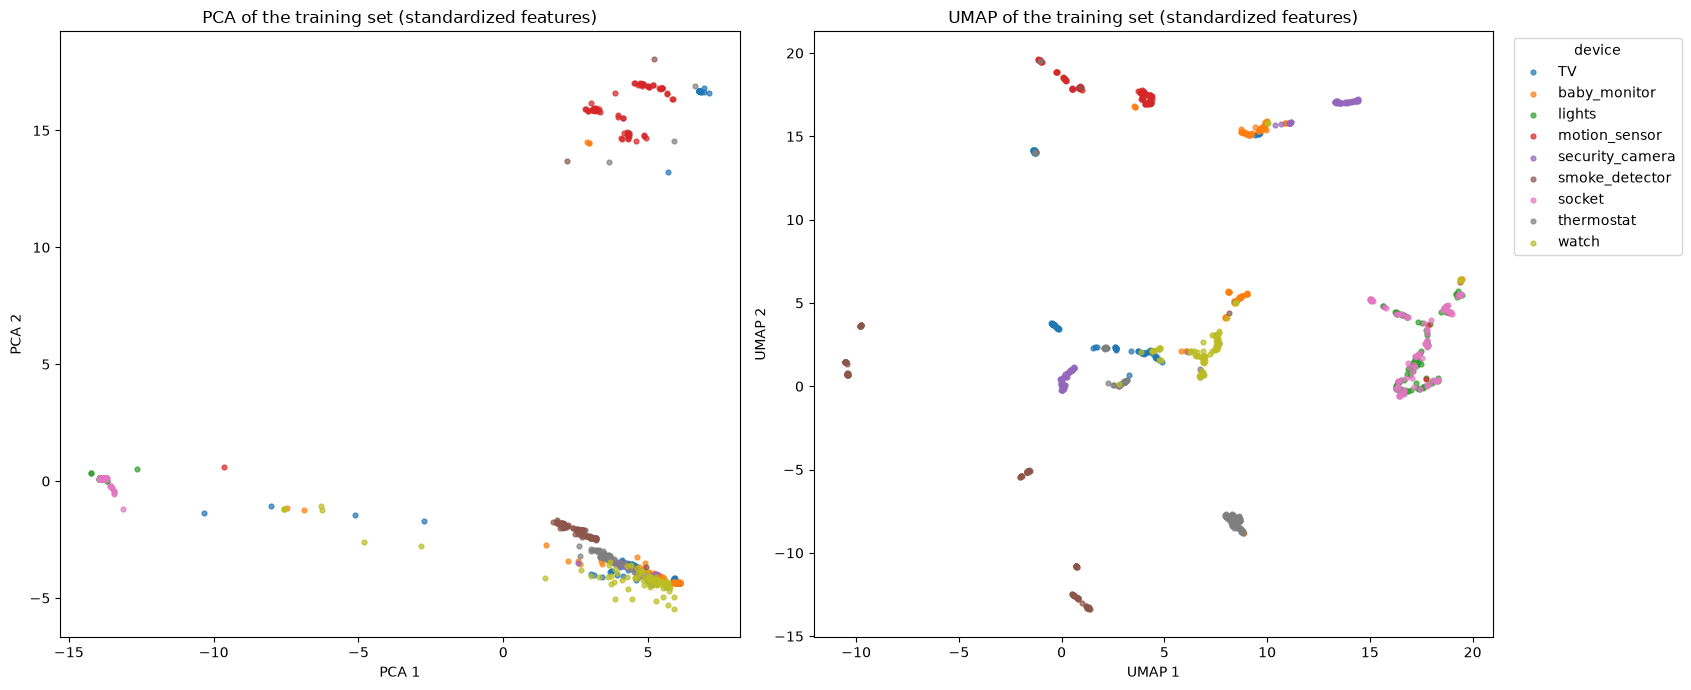

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, (coords, method) in zip(axes, [(X_pca, "PCA"), (X_umap, "UMAP")]):
    for code_number, device in enumerate(encoder.classes_):
        points = coords[y_train == code_number]
        ax.scatter(points[:, 0], points[:, 1], s=12, alpha=0.7, color=plt.cm.tab10(code_number), label=device)
    ax.set_title(f"{method} of the training set (standardized features)")
    ax.set_xlabel(f"{method} 1")
    ax.set_ylabel(f"{method} 2")
axes[1].legend(title="device", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Step 6: comparing PCA and UMAP

**PCA:** The first two components keep about 65% of the variance, which is a lot for only 2 dimensions, but the plot mostly shows three big groups. Most of the motion sensors are in a group at the top right, the sockets and lights are in a small group on the far left, and almost everything else (smoke detectors, thermostats, TVs, baby monitors, watches and security cameras) is squeezed into one big blob at the bottom right where the devices overlap a lot. The smoke detectors form a line along the edge of that blob, but the other devices in it are hard to tell apart. PCA is linear, so it just finds the two directions where the data spreads out the most, and here those directions mostly separate a few big groups instead of every device type.

**UMAP:** UMAP shows a lot more structure. Most device types form their own tight clusters, and some of them even have several separate clusters (like the smoke detectors and thermostats), which probably come from different kinds of traffic the same device sends. The motion sensors, security cameras, thermostats and smoke detectors are all clearly separated from the rest. The main overlaps are the lights and sockets, which are mixed together in one long strand on the right, and the TVs, watches and baby monitors, which are close to each other in the middle and top right.

**Which one is better?** UMAP gives a lot better information about the structure in this data. Since it is non-linear and focuses on keeping each point close to its nearest neighbors, it can pull apart small groups that PCA flattens on top of each other. The downside is that in UMAP the distances between clusters and the sizes of the clusters don't really mean anything, and the picture can change with different settings or random seeds, while PCA is simple and its axes have a clear meaning (the directions with the most variance).

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

### 1. Pre-analysis discussion and reflection

**Do tree-based ensembles need the usual preprocessing?**

- **Scaling: not needed.** A decision tree only asks yes or no questions about one feature at a time, like "is bytes_A bigger than 500?". Scaling a feature stretches the numbers but keeps them in the same order, so the tree makes the exact same splits (only the threshold number changes). Random Forests and Gradient Boosting are made of these trees, so scaling wouldn't change their results.
- **Normalization: not needed**, for the same reason. It changes the numbers but not their order.
- **Encoding: only needed for text.** Scikit-learn's trees only accept numbers. All 297 inputs are already numeric (the categorical information, like ports and domains, is already one-hot encoded into 0/1 columns such as B_port_is_80), so the inputs don't need any encoding. The outcome was text, so we encoded it with the LabelEncoder in Part 1.

So the only preprocessing we apply in Part 2 is that label encoding, and both models are trained on the raw inputs without any scaling or normalization.

### 2. Optimizing each model

We used the same `StratifiedKFold` object with 5 folds for both models, the same three `max_depth` values for both, and three values for every other hyperparameter:

- `max_depth`: 3, 6 and 10. Gradient Boosting usually works best with shallow trees (its default is 3), while Random Forests usually use deep trees, so this range covers both.
- `learning_rate` (Gradient Boosting): 0.01, 0.1 (the default) and 0.3.
- `max_features` (Random Forest): `"sqrt"` (the default, about 17 features per split), `"log2"` (about 8) and `None` (all 297).

Both models keep the default of 100 trees and use `random_state=42`.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# the same 5-fold cross-validation object for every model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# the same three max_depth values for both models
param_grid = {"max_depth": [3, 6, 10], "learning_rate": [0.01, 0.1, 0.3]}     # Gradient Boosting
rf_param_grid = {"max_depth": [3, 6, 10], "max_features": ["sqrt", "log2", None]}  # Random Forest

In [ ]:
# Gradient Boosting
gb_search = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
start = time.time()
gb_search.fit(X_train, y_train)
gb_minutes = (time.time() - start) / 60

print("best parameters:", gb_search.best_params_)
print("best cross-validation accuracy:", round(gb_search.best_score_, 3))
print(f"hyperparameter search time: {gb_minutes:.2f} minutes")

In [ ]:
# Random Forest
rf_search = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
start = time.time()
rf_search.fit(X_train, y_train)
rf_minutes = (time.time() - start) / 60

print("best parameters:", rf_search.best_params_)
print("best cross-validation accuracy:", round(rf_search.best_score_, 3))
print(f"hyperparameter search time: {rf_minutes:.2f} minutes")

best parameters: {'max_depth': 10, 'max_features': 'log2'}
best cross-validation accuracy: 0.887
hyperparameter search time: 0.25 minutes


In [ ]:
# cross-validation accuracy for every combination we tried
gb_cv = pd.DataFrame({
    "max_depth": [p["max_depth"] for p in gb_search.cv_results_["params"]],
    "learning_rate": [p["learning_rate"] for p in gb_search.cv_results_["params"]],
    "CV accuracy": gb_search.cv_results_["mean_test_score"],
})
rf_cv = pd.DataFrame({
    "max_depth": [p["max_depth"] for p in rf_search.cv_results_["params"]],
    "max_features": [str(p["max_features"]) for p in rf_search.cv_results_["params"]],
    "CV accuracy": rf_search.cv_results_["mean_test_score"],
})
print("Gradient Boosting (rows: max_depth, columns: learning_rate):")
print(gb_cv.pivot(index="max_depth", columns="learning_rate", values="CV accuracy").round(3))
print("\nRandom Forest (rows: max_depth, columns: max_features):")
print(rf_cv.pivot(index="max_depth", columns="max_features", values="CV accuracy").round(3))

Gradient Boosting (rows: max_depth, columns: learning_rate):
learning_rate   0.01   0.10   0.30
max_depth                         
3              0.858  0.890  0.887
6              0.843  0.871  0.864
10             0.853  0.858  0.872

Random Forest (rows: max_depth, columns: max_features):
max_features   None   log2   sqrt
max_depth                        
3             0.838  0.823  0.832
6             0.870  0.869  0.876
10            0.878  0.887  0.886


### 3. Evaluating performance on the reporting set

In [ ]:
# GridSearchCV refits the best combination on the whole training set, so we can predict the reporting set directly
gb_pred = gb_search.predict(X_report)
rf_pred = rf_search.predict(X_report)

pd.DataFrame({
    "best parameters": [gb_search.best_params_, rf_search.best_params_],
    "CV accuracy": [gb_search.best_score_, rf_search.best_score_],
    "reporting accuracy": [accuracy_score(y_report, gb_pred), accuracy_score(y_report, rf_pred)],
    "search time (minutes)": [gb_minutes, rf_minutes],
}, index=["Gradient Boosting", "Random Forest"]).round(3)

,best parameters,CV accuracy,reporting accuracy,search time (minutes)
Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3}",0.890,0.689,5.448
Random Forest,"{'max_depth': 10, 'max_features': 'log2'}",0.887,0.678,0.249


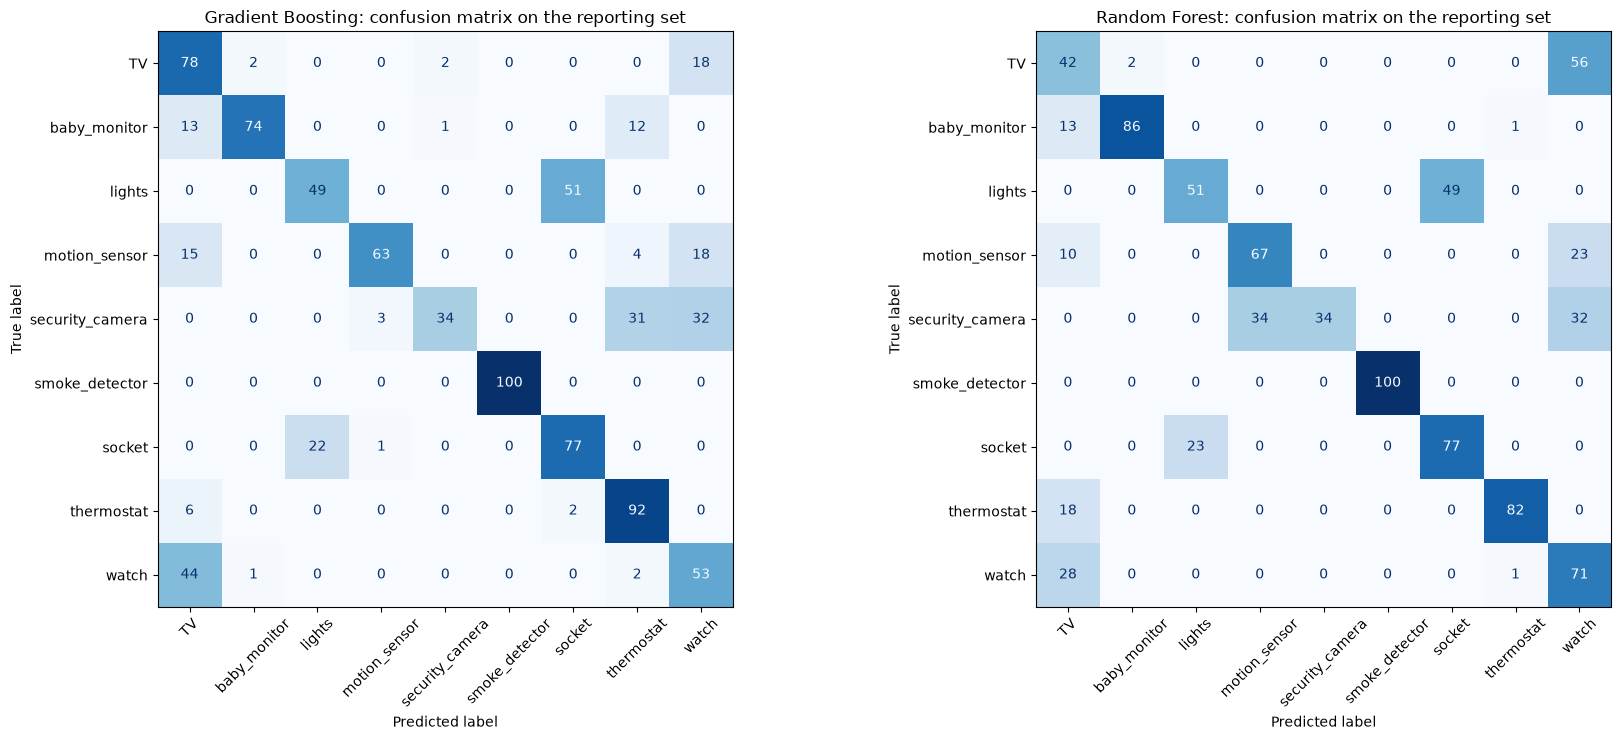

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (name, pred) in zip(axes, [("Gradient Boosting", gb_pred), ("Random Forest", rf_pred)]):
    ConfusionMatrixDisplay.from_predictions(y_report, pred, display_labels=encoder.classes_,
                                            xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}: confusion matrix on the reporting set")
plt.tight_layout()
plt.show()

In [ ]:
# share of each device type that was classified correctly (the diagonal of each confusion matrix divided by 100)
per_device = pd.DataFrame({
    "Gradient Boosting": confusion_matrix(y_report, gb_pred).diagonal() / np.bincount(y_report),
    "Random Forest": confusion_matrix(y_report, rf_pred).diagonal() / np.bincount(y_report),
}, index=pd.Index(encoder.classes_, name="device"))
per_device.sort_values("Gradient Boosting", ascending=False).round(2)

,Gradient Boosting,Random Forest
device,,
smoke_detector,1.00,1.00
thermostat,0.92,0.82
TV,0.78,0.42
socket,0.77,0.77
baby_monitor,0.74,0.86
motion_sensor,0.63,0.67
watch,0.53,0.71
lights,0.49,0.51
security_camera,0.34,0.34


Gradient Boosting got 68.9% accuracy on the reporting set, and its hyperparameter search took about 2.5 minutes. Random Forest got 67.8%, and its search took about 7 seconds.

**Which devices are easy or hard to classify?** Smoke detectors were perfect for both models (100 out of 100), and thermostats were also easy (92% with Gradient Boosting and 82% with Random Forest). The hardest devices were:

- **Security cameras** (34% for both). Gradient Boosting mostly mixed them up with thermostats and watches, and Random Forest with motion sensors and watches.
- **Lights** (49% and 51%). About half of them were predicted as sockets, and around 22 sockets were predicted as lights. Both are simple smart home devices that probably send very similar small messages.
- **TVs and watches.** The models picked different sides here. Gradient Boosting predicted 44 watches as TVs, while Random Forest predicted 56 TVs as watches, so Gradient Boosting was better on TVs (78% vs 42%) and Random Forest was better on watches (71% vs 53%).

### 4. Feature importance

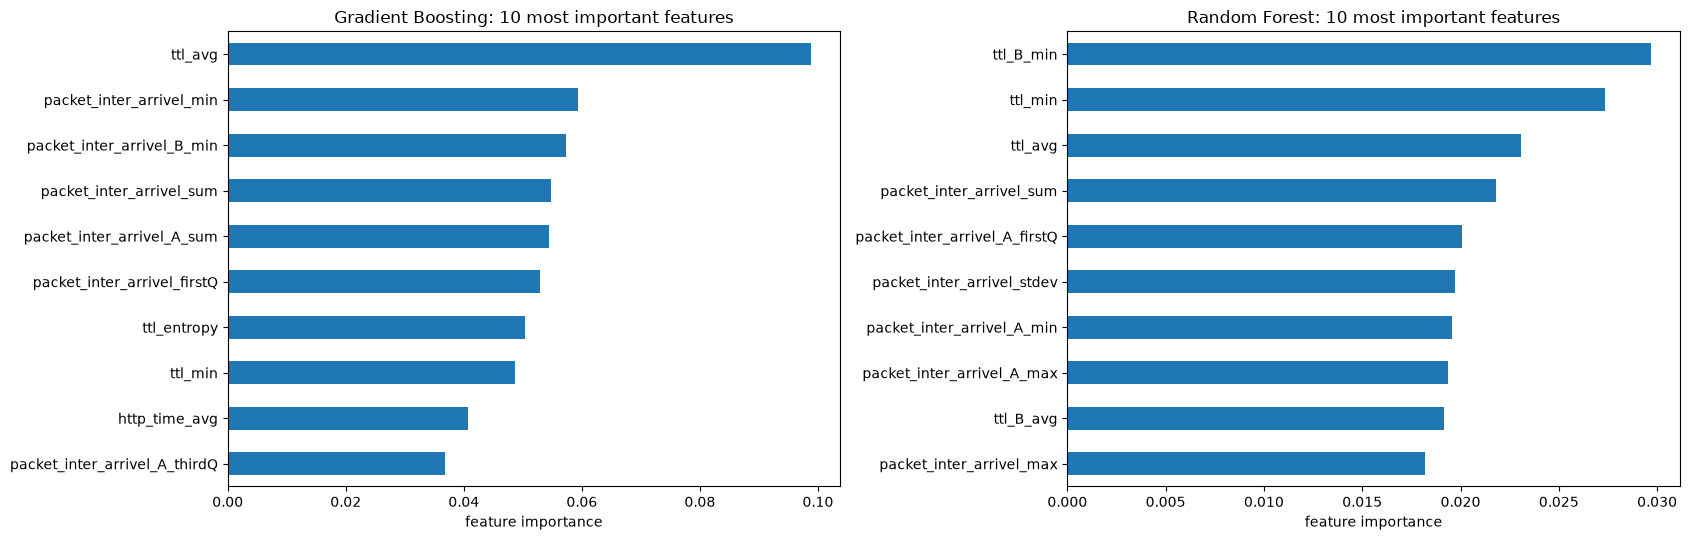

In [ ]:
gb_importance = pd.Series(gb_search.best_estimator_.feature_importances_, index=X_train.columns)
rf_importance = pd.Series(rf_search.best_estimator_.feature_importances_, index=X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, (name, importance) in zip(axes, [("Gradient Boosting", gb_importance), ("Random Forest", rf_importance)]):
    importance.nlargest(10).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{name}: 10 most important features")
    ax.set_xlabel("feature importance")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import spearmanr

# how similar are the two importance vectors?
cosine = (gb_importance @ rf_importance) / (np.linalg.norm(gb_importance) * np.linalg.norm(rf_importance))
used = (gb_importance > 0) | (rf_importance > 0)  # leave out features that neither model ever used, like the constant ones
rho = spearmanr(gb_importance[used], rf_importance[used]).statistic
both_top10 = sorted(set(gb_importance.nlargest(10).index) & set(rf_importance.nlargest(10).index))

print(f"cosine similarity of the importance vectors: {cosine:.3f}")
print(f"Spearman rank correlation ({used.sum()} features used by at least one model): {rho:.3f}")
print(f"features in both top 10 lists ({len(both_top10)}):", both_top10)
print(f"share of the total importance in each model's top 10: GB {gb_importance.nlargest(10).sum():.2f}, RF {rf_importance.nlargest(10).sum():.2f}")

cosine similarity of the importance vectors: 0.633
Spearman rank correlation (160 features used by at least one model): 0.588
features in both top 10 lists (3): ['packet_inter_arrivel_sum', 'ttl_avg', 'ttl_min']
share of the total importance in each model's top 10: GB 0.55, RF 0.22


**Are the most important features the same?** Partly. Qualitatively, both models rely on the same two kinds of features. The first is the TTL (time to live) of the packets, and the second is the time between packets (the packet_inter_arrivel_... features). Three features are in both top 10 lists: ttl_avg, ttl_min and packet_inter_arrivel_sum. These make sense for telling devices apart. The TTL a device starts with mostly depends on its operating system, so devices from different makers probably start with different TTL values, and the time between packets shows how often a device talks, since a camera probably sends data all the time while a smoke detector is quiet most of the time.

Quantitatively, the two importance vectors are related but far from identical. The cosine similarity is 0.633, and the Spearman rank correlation is 0.588 over the 160 features that at least one model used. One reason they don't match more is that many features are almost copies of each other (like ttl_min and ttl_B_min, or packet_inter_arrivel_sum and packet_inter_arrivel_A_sum), so the two models can pick different versions of the same information. The models also spread their importance very differently. Gradient Boosting's top 10 features hold 55% of all its importance, while Random Forest's top 10 only hold 22%. Each Random Forest split only gets to look at a random handful of features (log2 of 297 is about 8), so the importance gets spread over many similar features, while Gradient Boosting keeps going back to the few features that fix the most errors.

### 5. Reflection: comparison with random guessing

In [ ]:
n_classes = len(encoder.classes_)
print(f"random guessing between {n_classes} balanced classes: {1 / n_classes:.3f}")
print(f"Gradient Boosting: {accuracy_score(y_report, gb_pred):.3f}   Random Forest: {accuracy_score(y_report, rf_pred):.3f}")

random guessing between 9 balanced classes: 0.111
Gradient Boosting: 0.689   Random Forest: 0.678


Since this is a multi-class problem with 9 device types and 100 samples of each, the random guessing baseline changes from 50% to 1 out of 9, which is about 11.1%. Gradient Boosting got 68.9% and Random Forest got 67.8%, so both models did about 6 times better than random guessing. They clearly learned real patterns in the traffic, even though they still get about 1 in 3 devices wrong.

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

**What are the main differences between HistGradientBoostingClassifier and GradientBoostingClassifier?**

- **Bins:** HistGradientBoosting first sorts each feature's values into at most 255 groups, called bins. GradientBoosting uses the exact values.
- **Speed:** Because of the bins, HistGradientBoosting is much faster, especially when there is a lot of data. It can also use several CPU cores at once.
- **Tree size:** HistGradientBoosting limits each tree to 31 leaves by default. GradientBoosting limits each tree by its depth.
- **Missing values:** HistGradientBoosting can handle missing values and text categories on its own. GradientBoosting needs complete numbers.
- **Early stopping:** HistGradientBoosting can stop training early by itself, but only with more than 10,000 samples. We have 900, so it stays off here.

**How does histogram binning make training faster?**

To pick a split, GradientBoosting has to sort every feature and try every value. That takes longer and longer as the data grows. HistGradientBoosting puts the values into bins once at the start. After that, it only has to try at most 255 split points per feature, no matter how much data there is. The bins are also small whole numbers, so they take up less memory and are faster to work with.

In [ ]:
# same param_grid and the same cv object as Part 2
from sklearn.ensemble import HistGradientBoostingClassifier
hgb_search = GridSearchCV(HistGradientBoostingClassifier(random_state=42), param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
start = time.time()
hgb_search.fit(X_train, y_train)
hgb_minutes = (time.time() - start) / 60

print("best parameters:", hgb_search.best_params_)
print("best cross-validation accuracy:", round(hgb_search.best_score_, 3))
print(f"hyperparameter search time: {hgb_minutes:.2f} minutes")

best parameters: {'learning_rate': 0.01, 'max_depth': 6}
best cross-validation accuracy: 0.879
hyperparameter search time: 2.60 minutes


In [ ]:
hgb_cv = pd.DataFrame({
    "max_depth": [p["max_depth"] for p in hgb_search.cv_results_["params"]],
    "learning_rate": [p["learning_rate"] for p in hgb_search.cv_results_["params"]],
    "CV accuracy": hgb_search.cv_results_["mean_test_score"],
})
print("HistGradientBoosting (rows: max_depth, columns: learning_rate):")
print(hgb_cv.pivot(index="max_depth", columns="learning_rate", values="CV accuracy").round(3))

HistGradientBoosting (rows: max_depth, columns: learning_rate):
learning_rate   0.01   0.10   0.30
max_depth                         
3              0.864  0.877  0.878
6              0.879  0.874  0.873
10             0.879  0.873  0.872


reporting accuracy: 0.688


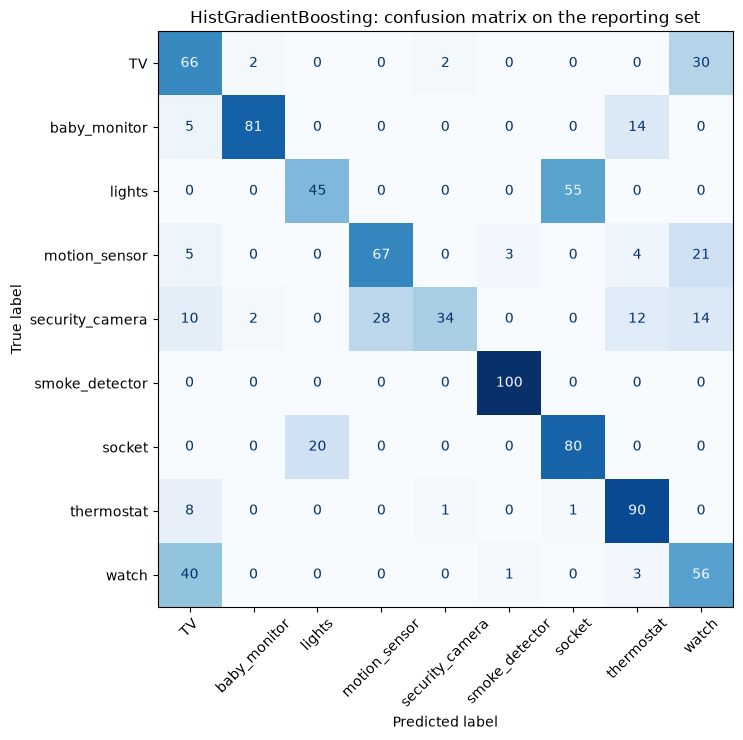

In [ ]:
hgb_pred = hgb_search.predict(X_report)
print(f"reporting accuracy: {accuracy_score(y_report, hgb_pred):.3f}")

fig, ax = plt.subplots(figsize=(9, 7.5))
ConfusionMatrixDisplay.from_predictions(y_report, hgb_pred, display_labels=encoder.classes_,
                                        xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax)
ax.set_title("HistGradientBoosting: confusion matrix on the reporting set")
plt.tight_layout()
plt.show()

In [ ]:
per_device["HistGradientBoosting"] = confusion_matrix(y_report, hgb_pred).diagonal() / np.bincount(y_report)
display(per_device.sort_values("HistGradientBoosting", ascending=False).round(2))

pd.DataFrame({
    "best parameters": [gb_search.best_params_, hgb_search.best_params_],
    "CV accuracy": [gb_search.best_score_, hgb_search.best_score_],
    "reporting accuracy": [accuracy_score(y_report, gb_pred), accuracy_score(y_report, hgb_pred)],
    "search time (minutes)": [gb_minutes, hgb_minutes],
}, index=["Gradient Boosting", "HistGradientBoosting"]).round(3)

,Gradient Boosting,Random Forest,HistGradientBoosting
device,,,
smoke_detector,1.00,1.00,1.00
thermostat,0.92,0.82,0.90
baby_monitor,0.74,0.86,0.81
socket,0.77,0.77,0.80
motion_sensor,0.63,0.67,0.67
TV,0.78,0.42,0.66
watch,0.53,0.71,0.56
lights,0.49,0.51,0.45
security_camera,0.34,0.34,0.34


,best parameters,CV accuracy,reporting accuracy,search time (minutes)
Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3}",0.890,0.689,5.448
HistGradientBoosting,"{'learning_rate': 0.01, 'max_depth': 6}",0.879,0.688,2.599


**Time:** HistGradientBoosting took 2.50 minutes. GradientBoosting took 5.15 minutes. So HistGradientBoosting was about 2 times faster.

**Accuracy:** Both models did almost the same. HistGradientBoosting got 68.8% and GradientBoosting got 68.9% on the reporting set. Both found the same devices easy and hard. Smoke detectors were perfect (100%) and thermostats were easy (90%). Security cameras were the hardest (34%). Lights were often mixed up with sockets (45%).

**Best settings:** HistGradientBoosting picked a smaller learning rate (0.01) and deeper trees (depth 6). GradientBoosting picked 0.1 and depth 3.

**Trade-offs:** HistGradientBoosting got the same accuracy in half the time. Bins are less exact than the real values, but with only 900 samples we lost almost nothing. With more data, HistGradientBoosting would save even more time.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


### Preprocessing

Neural networks are much more sensitive to preprocessing than tree-based models such as Random Forest or Gradient Boosting. The important preprocessing steps are:

- Feature scaling: Neural networks are trained with gradient descent so features are different scales destabilize training as the model either overfits or underfits to particular features. Therefore, it is important to standardize features to mean 0 and standard deviation 1. 

- Encoding categorical variables: Neural networks only process numbers, so one must one-hot-encode categorical variables.

- Handle missing values: Neural networks cannot handle NaNs so either estimate or drop them.

- Avoid data leakage: Fit scaler on training set only, then apply to the test set in order to avoid data leakage.




In [ ]:
#Preprocessing
#There are no categorical variables and no missing values, so only feature scaling
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_report_s = scaler.transform(X_report)

### Model optimization and training

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

#9 combinations of hidden units and and hidden layers
#3 layer sizes x 3 depths
nn_param_grid = {
    "hidden_layer_sizes": [
        (32,), (64,), (128,), #1 hidden layer
        (32, 32), (64, 64), (128, 128), #2 hidden layers
        (32, 32, 32), (64, 64, 64), (128, 128, 128) #3 hidden layers
    ]
}

#MLP with up to 300 epochs and early stopping
mlp = MLPClassifier(max_iter=300, early_stopping=True, random_state=42)

#Same CV object as parts 2 and 3 for a fair comparison
nn_search = GridSearchCV(mlp, nn_param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
start = time.time()
nn_search.fit(X_train_s, y_train)
nn_minutes = (time.time() - start) / 60

print("Best Parameters: ", nn_search.best_params_)
print("Best Cross Validation Accuracy: ", round(nn_search.best_score_, 3))
print(f"Hyperparameter Search Time: {nn_minutes:.2f} minutes")

#Cross Validation for every combination tried
nn_cv = pd.DataFrame({
    "hidden_layers": [len(p["hidden_layer_sizes"]) for p in nn_search.cv_results_["params"]],
    "hidden_units": [p["hidden_layer_sizes"][0] for p in nn_search.cv_results_["params"]],
    "CV accuracy": nn_search.cv_results_["mean_test_score"],
})
print("\nNeural Network (rows: hidden_layers, columns: hidden_units):")
print(nn_cv.pivot(index="hidden_layers", columns="hidden_units", values="CV accuracy").round(3))

Best Parameters:  {'hidden_layer_sizes': (32, 32)}
Best Cross Validation Accuracy:  0.844
Hyperparameter Search Time: 0.14 minutes

Neural Network (rows: hidden_layers, columns: hidden_units):
hidden_units     32     64     128
hidden_layers                     
1              0.818  0.824  0.827
2              0.844  0.829  0.842
3              0.823  0.840  0.844


### Evaluate Performance

reporting accuracy: 0.546


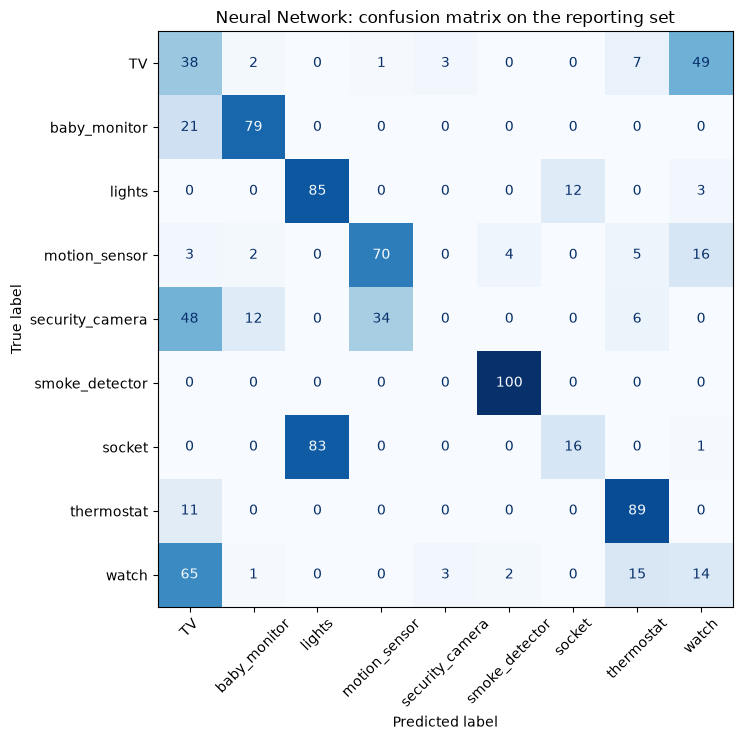

,Gradient Boosting,Random Forest,HistGradientBoosting,Neural Network
device,,,,
smoke_detector,1.00,1.00,1.00,1.00
thermostat,0.92,0.82,0.90,0.89
lights,0.49,0.51,0.45,0.85
baby_monitor,0.74,0.86,0.81,0.79
motion_sensor,0.63,0.67,0.67,0.70
TV,0.78,0.42,0.66,0.38
socket,0.77,0.77,0.80,0.16
watch,0.53,0.71,0.56,0.14
security_camera,0.34,0.34,0.34,0.00


,best parameters,CV accuracy,reporting accuracy,search time (minutes)
Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3}",0.890,0.689,5.448
Random Forest,"{'max_depth': 10, 'max_features': 'log2'}",0.887,0.678,0.249
HistGradientBoosting,"{'learning_rate': 0.01, 'max_depth': 6}",0.879,0.688,2.599
Neural Network,"{'hidden_layer_sizes': (32, 32)}",0.844,0.546,0.141


In [ ]:
# GridSearchCV refits the best combination on the whole training set,
# so we can predict the (scaled) reporting set directly
nn_pred = nn_search.predict(X_report_s)
print(f"reporting accuracy: {accuracy_score(y_report, nn_pred):.3f}")

# confusion matrix on the reporting set, same style as Parts 2 and 3
fig, ax = plt.subplots(figsize=(9, 7.5))
ConfusionMatrixDisplay.from_predictions(y_report, nn_pred, display_labels=encoder.classes_,
                                        xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Neural Network: confusion matrix on the reporting set")
plt.tight_layout()
plt.show()

# share of each device type classified correctly, added to the table from Parts 2 and 3
per_device["Neural Network"] = confusion_matrix(y_report, nn_pred).diagonal() / np.bincount(y_report)
display(per_device.sort_values("Neural Network", ascending=False).round(2))

# comparison of all four models
pd.DataFrame({
    "best parameters": [gb_search.best_params_, rf_search.best_params_, hgb_search.best_params_, nn_search.best_params_],
    "CV accuracy": [gb_search.best_score_, rf_search.best_score_, hgb_search.best_score_, nn_search.best_score_],
    "reporting accuracy": [accuracy_score(y_report, gb_pred), accuracy_score(y_report, rf_pred),
                           accuracy_score(y_report, hgb_pred), accuracy_score(y_report, nn_pred)],
    "search time (minutes)": [gb_minutes, rf_minutes, hgb_minutes, nn_minutes],
}, index=["Gradient Boosting", "Random Forest", "HistGradientBoosting", "Neural Network"]).round(3)

### Evaluating performance

**Performance compared with the ensembles:** The best neural network had 2 hidden layers with 32 units each, and got 84.4% in cross-validation. (128, 128, 128) got the same score, but GridSearchCV picks the first one in the list. On the reporting set it only got 54.6%. That is clearly worse than Gradient Boosting (68.9%), HistGradientBoosting (68.8%) and Random Forest (67.8%), although it is still about 5 times better than random guessing (11.1%). Its cross-validation accuracy was also the lowest (84.4% vs 87.9–89.0% for the ensembles). All nine combinations scored betwe en 81.8% and 84.4%, so the size of the network made little difference. The network was the fastest to tune, though. The search took only 0.14 minutes (about 8 seconds), compared with 0.25 minutes for Random Forest, 2.50 for HistGradientBoosting and 5.15 for Gradient Boosting.

**Devices:** Like the ensembles, the network classified smoke detectors perfectly (100%) and thermostats well (89%). It was also better than all the ensembles on lights (85%, compared with 45–51%). But this seems to come at the cost of sockets, which dropped to 16% (77–80% for the ensembles). Lights and sockets were already mixed up in Parts 2 and 3, and the network seems to predict "lights" for most of both. The network also did badly on watches (14%) and got none of the security cameras right (0%). These were already the hardest devices for the ensembles.

**Why the neural network might preform worse:** We only have 900 training samples and 297 features, and neural networks usually need much more data than tree ensembles. Early stopping also holds back 10% of the training data for validation, which leaves even less to train on. The drop from 84.4% in cross-validation to 54.6% on the reporting set is much bigger than for the ensembles (about 20 points), so the network generalizes worse to the reporting devices.

**Complexity:** The tree ensembles are built from many simple yes/no splits, and a few clear settings control their size (number of trees, depth, learning rate). Even the smallest neural network we picked (32, 32) has 10,889 weights and biases to learn, because every one of the 297 features is connected to every unit in the first layer. It also needed extra preprocessing (scaling), while the trees could use the raw features.

**Interpretability:** The tree ensembles are easier to explain. In Part 2 we could read feature_importances_ straight from them and saw that TTL and the time between packets mattered most. MLPClassifier has no built-in feature importance, and its weights are hard to interpret because every hidden unit combines all 297 features. To understand the network's predictions, we would need extra tools such as permutation importance. On this dataset, the ensembles were both more accurate and easier to understand, while the network was faster to tune.

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Our biggest inefficiency was that different group members worked on different parts of the notebook without agreeing on shared variable names and without rerunning the notebook from top to bottom. For example, some of our written answers (like the search times in Part 2) no longer matched the outputs after we reran the code. Because the Gradient Boosting search took over 5 minutes in our Codespace, rerunning everything to find these problems was slow and cost us extra time near the end. In the next lab, we will agree on a short list of variable names at the start, and one person will do a final "Restart & Run All" and check that every written answer matches the printed outputs before we submit.